In [1]:
"""
Assignment 3 - Task 2: Curve-inversion recession signal
-------------------------------------------------------
1. Build two yield-curve spreads (monthly, longest free history):
     2s10s = 10y - 2y   (GS10 - GS2,   from 1976)
     3m10y = 10y - 3m   (GS10 - TB3MS, from 1953)
2. Mark NBER recessions (USREC). For every inversion episode (spread < 0),
   measure the months until the next recession and count false signals.
3. Compare two timing rules against buy-and-hold stocks:
     Rule A: switch stocks -> T-bills when the curve INVERTS
     Rule B: switch stocks -> T-bills when the curve UN-INVERTS (after an inversion)
   In both rules the portfolio stays in T-bills for HOLD months, then returns to stocks.

Data (free, no API key):
  * FRED CSV download: GS10, GS2, TB3MS, USREC
  * Ken French data library: US market total return (Mkt-RF + RF) and T-bill return (RF)

Run in VS Code / Jupyter with the team environment (uv sync). Needs pandas, numpy,
matplotlib, requests (all already in pyproject.toml).
"""

'\nAssignment 3 - Task 2: Curve-inversion recession signal\n-------------------------------------------------------\n1. Build two yield-curve spreads (monthly, longest free history):\n     2s10s = 10y - 2y   (GS10 - GS2,   from 1976)\n     3m10y = 10y - 3m   (GS10 - TB3MS, from 1953)\n2. Mark NBER recessions (USREC). For every inversion episode (spread < 0),\n   measure the months until the next recession and count false signals.\n3. Compare two timing rules against buy-and-hold stocks:\n     Rule A: switch stocks -> T-bills when the curve INVERTS\n     Rule B: switch stocks -> T-bills when the curve UN-INVERTS (after an inversion)\n   In both rules the portfolio stays in T-bills for HOLD months, then returns to stocks.\n\nData (free, no API key):\n  * FRED CSV download: GS10, GS2, TB3MS, USREC\n  * Ken French data library: US market total return (Mkt-RF + RF) and T-bill return (RF)\n\nRun in VS Code / Jupyter with the team environment (uv sync). Needs pandas, numpy,\nmatplotlib, reque

In [2]:
import io
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

OUT = Path("../data/task2")          
OUT.mkdir(parents=True, exist_ok=True)

MERGE_GAP = 12   
MAX_LEAD = 24    
HOLD = 18        


def months_between(a, b):
    """Whole months from date a to date b."""
    return (b.year - a.year) * 12 + (b.month - a.month)

In [3]:
def fred(series_id):
    """Monthly FRED series via the public CSV endpoint (no API key needed)."""
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    s = pd.read_csv(url, index_col=0, parse_dates=True, na_values=".").iloc[:, 0]
    s.index = s.index.to_period("M").to_timestamp()
    return s.rename(series_id)


def ff_monthly():
    """US market total return and T-bill return (decimals), Ken French library."""
    url = ("https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"
           "F-F_Research_Data_Factors_CSV.zip")
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    z = zipfile.ZipFile(io.BytesIO(r.content))
    lines = z.read(z.namelist()[0]).decode("latin-1").splitlines()
    start = next(i for i, line in enumerate(lines) if line.strip().startswith(",Mkt-RF"))
    rows = []
    for line in lines[start + 1:]:
        parts = [p.strip() for p in line.split(",")]
        if len(parts[0]) != 6 or not parts[0].isdigit():   # monthly block ends here
            break
        rows.append(parts[:5])
    df = pd.DataFrame(rows, columns=["date", "Mkt-RF", "SMB", "HML", "RF"])
    df.index = pd.to_datetime(df.pop("date"), format="%Y%m")
    df = df.astype(float) / 100
    return pd.DataFrame({"stock": df["Mkt-RF"] + df["RF"], "bill": df["RF"]})


macro = pd.concat([fred(s) for s in ["GS10", "GS2", "TB3MS", "USREC"]], axis=1)
macro["2s10s"] = macro["GS10"] - macro["GS2"]
macro["3m10y"] = macro["GS10"] - macro["TB3MS"]
rets = ff_monthly()

macro.to_csv(OUT / "spreads_monthly.csv")
print(macro[["2s10s", "3m10y"]].dropna(how="all").agg(["first_valid_index", "last_valid_index"]))

/var/folders/gx/7d5rj7x93xjcfdj0kdf8lyt80000gn/T/ipykernel_73478/27673334.py:30: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  macro = pd.concat([fred(s) for s in ["GS10", "GS2", "TB3MS", "USREC"]], axis=1)


                       2s10s      3m10y
first_valid_index 1976-06-01 1953-04-01
last_valid_index  2026-09-01 2026-09-01


In [4]:
rec = macro["USREC"].dropna()
rec_start = rec.index[(rec == 1) & (rec.shift(1) == 0)]
rec_end_all = rec.index[(rec == 1) & (rec.shift(-1) == 0)]
rec_end = pd.DatetimeIndex([rec_end_all[rec_end_all >= s][0] for s in rec_start])


def inversion_episodes(spread, merge_gap=MERGE_GAP):
    """List of [first inverted month, last inverted month].
    Inversions that restart within `merge_gap` months are merged into one episode."""
    s = spread.dropna()
    neg = s < 0
    starts = s.index[neg & ~neg.shift(1, fill_value=False)]
    ends = s.index[neg & ~neg.shift(-1, fill_value=False)]
    episodes = []
    for st, en in zip(starts, ends):
        if episodes and months_between(episodes[-1][1], st) <= merge_gap:
            episodes[-1][1] = en
        else:
            episodes.append([st, en])
    return episodes


def signal_table(name):
    spread = macro[name]
    rows = []
    for st, en in inversion_episodes(spread):
        nxt = rec_start[rec_start >= st]
        nxt = nxt[0] if len(nxt) else pd.NaT
        lead = months_between(st, nxt) if pd.notna(nxt) else np.nan
        uninv = en + pd.DateOffset(months=1)
        rows.append({
            "spread": name,
            "inversion_start": st.date(),
            "inversion_end": en.date(),
            "months_inverted": months_between(st, en) + 1,
            "min_spread": round(spread.loc[st:en].min(), 2),
            "next_recession": nxt.date() if pd.notna(nxt) else None,
            "lead_from_inversion": lead,
            "lead_from_uninversion": months_between(uninv, nxt) if pd.notna(nxt) else np.nan,
            "true_signal": bool(pd.notna(nxt) and lead <= MAX_LEAD),
        })
    return pd.DataFrame(rows)


def missed_recessions(name, table):
    s = macro[name]
    first = s.first_valid_index()
    missed = []
    for r0 in rec_start[rec_start > first + pd.DateOffset(months=MAX_LEAD)]:
        window = s.loc[r0 - pd.DateOffset(months=MAX_LEAD): r0]
        if not (window < 0).any():
            missed.append(r0.date())
    return missed
 

report = []
tables = {}
for name in ["2s10s", "3m10y"]:
    t = signal_table(name)
    tables[name] = t
    true = t[t["true_signal"]]
    summary = (
        f"\n=== {name} (sample from {macro[name].first_valid_index().date()}) ===\n"
        f"Inversion episodes: {len(t)} | followed by recession within {MAX_LEAD}m: {len(true)} "
        f"| false signals: {len(t) - len(true)}\n"
        f"Lead time from inversion (true signals): mean {true['lead_from_inversion'].mean():.1f}, "
        f"min {true['lead_from_inversion'].min():.0f}, max {true['lead_from_inversion'].max():.0f} months\n"
        f"Lead time from un-inversion (true signals): mean {true['lead_from_uninversion'].mean():.1f}, "
        f"min {true['lead_from_uninversion'].min():.0f}, max {true['lead_from_uninversion'].max():.0f} months\n"
        f"Recessions not preceded by an inversion: {missed_recessions(name, t) or 'none'}\n"
    )
    report.append(summary + t.to_string(index=False))
    print(summary)
    print(t.to_string(index=False))

pd.concat(tables.values()).to_csv(OUT / "inversion_episodes.csv", index=False)


=== 2s10s (sample from 1976-06-01) ===
Inversion episodes: 6 | followed by recession within 24m: 4 | false signals: 2
Lead time from inversion (true signals): mean 18.2, min 14, max 23 months
Lead time from un-inversion (true signals): mean -3.8, min -29, max 7 months
Recessions not preceded by an inversion: [datetime.date(2020, 3, 1)]

spread inversion_start inversion_end  months_inverted  min_spread next_recession  lead_from_inversion  lead_from_uninversion  true_signal
 2s10s      1978-09-01    1982-06-01               46       -2.13     1980-02-01                 17.0                  -29.0         True
 2s10s      1989-01-01    1990-03-01               15       -0.32     1990-08-01                 19.0                    4.0         True
 2s10s      1998-06-01    1998-06-01                1       -0.02     2001-04-01                 34.0                   33.0        False
 2s10s      2000-02-01    2000-12-01               11       -0.41     2001-04-01                 14.0       

In [5]:
def bills_mask(index, triggers, hold=HOLD):
    """True in the months the rule holds T-bills.
    Signal is known at the end of month t -> trade from month t+1 (no look-ahead)."""
    mask = pd.Series(False, index=index)
    for t in triggers:
        lo = t + pd.DateOffset(months=1)
        hi = t + pd.DateOffset(months=hold)
        mask.loc[lo:hi] = True
    return mask


def perf(r, rf):
    wealth = (1 + r).cumprod()
    excess = r - rf
    return {
        "Ann. return": (1 + r).prod() ** (12 / len(r)) - 1,
        "Ann. vol": r.std() * np.sqrt(12),
        "Sharpe": excess.mean() / excess.std() * np.sqrt(12),
        "Max drawdown": (wealth / wealth.cummax() - 1).min(),
    }


results = {}
wealth_curves = {}
for name in ["2s10s", "3m10y"]:
    eps = inversion_episodes(macro[name])
    start = max(macro[name].first_valid_index(), rets.index[0])
    end = min(macro[name].last_valid_index(), rets.index[-1])
    r = rets.loc[start:end]

    trig_a = [st for st, _ in eps]                                   # inversion month
    trig_b = [en + pd.DateOffset(months=1) for _, en in eps          # first month back >= 0
              if en + pd.DateOffset(months=1) <= end]
    mask_a = bills_mask(r.index, trig_a)
    mask_b = bills_mask(r.index, trig_b)

    strat = {
        "Buy & hold stocks": r["stock"],
        "Rule A (invert)": r["stock"].where(~mask_a, r["bill"]),
        "Rule B (un-invert)": r["stock"].where(~mask_b, r["bill"]),
    }
    tbl = pd.DataFrame({k: perf(v, r["bill"]) for k, v in strat.items()}).T
    tbl["% months in bills"] = [0.0, mask_a.mean(), mask_b.mean()]
    results[name] = tbl
    wealth_curves[name] = pd.DataFrame({k: (1 + v).cumprod() for k, v in strat.items()})

    block = (f"\n=== Rules on {name}: {r.index[0].date()} to {r.index[-1].date()}, "
             f"hold {HOLD}m in T-bills ===\n{tbl.round(3).to_string()}")
    report.append(block)
    print(block)

(OUT / "results.txt").write_text("\n".join(report));


=== Rules on 2s10s: 1976-06-01 to 2026-09-01, hold 18m in T-bills ===
                    Ann. return  Ann. vol  Sharpe  Max drawdown  % months in bills
Buy & hold stocks         0.121     0.154   0.553        -0.503              0.000
Rule A (invert)           0.119     0.136   0.590        -0.503              0.179
Rule B (un-invert)        0.124     0.133   0.632        -0.299              0.179

=== Rules on 3m10y: 1953-04-01 to 2026-09-01, hold 18m in T-bills ===
                    Ann. return  Ann. vol  Sharpe  Max drawdown  % months in bills
Buy & hold stocks         0.113     0.150   0.522        -0.503              0.000
Rule A (invert)           0.120     0.131   0.626        -0.459              0.163
Rule B (un-invert)        0.105     0.132   0.516        -0.465              0.163


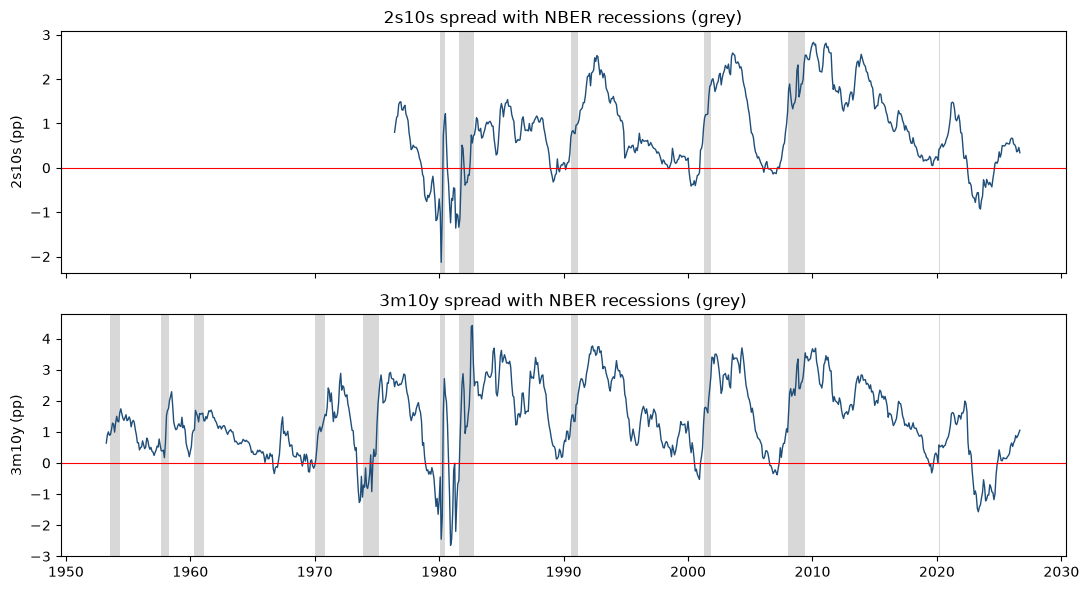

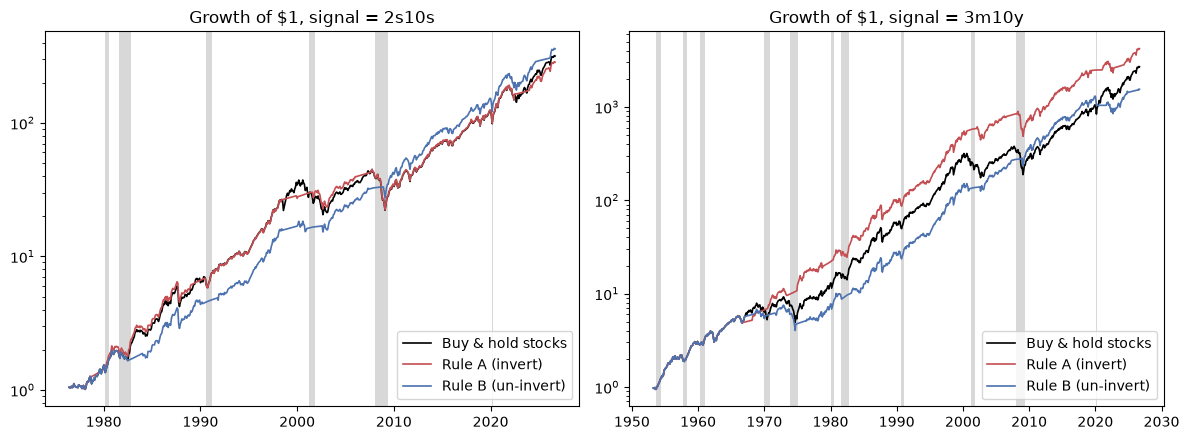


Done. Outputs in ../data/task2


In [6]:
def shade_recessions(ax, lo, hi):
    for a, b in zip(rec_start, rec_end):
        if b >= lo and a <= hi:
            ax.axvspan(a, b, color="grey", alpha=0.3, lw=0)


fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for ax, name in zip(axes, ["2s10s", "3m10y"]):
    s = macro[name].dropna()
    ax.plot(s.index, s, lw=1, color="#1f4e79")
    ax.axhline(0, color="red", lw=0.8)
    shade_recessions(ax, s.index[0], s.index[-1])
    ax.set_ylabel(f"{name} (pp)")
    ax.set_title(f"{name} spread with NBER recessions (grey)")
plt.tight_layout()
plt.savefig(OUT / "spreads_recessions.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, ["2s10s", "3m10y"]):
    w = wealth_curves[name]
    for col, c in zip(w.columns, ["black", "#c44e52", "#4c72b0"]):
        ax.plot(w.index, w[col], label=col, color=c, lw=1.2)
    shade_recessions(ax, w.index[0], w.index[-1])
    ax.set_yscale("log")
    ax.set_title(f"Growth of $1, signal = {name}")
    ax.legend()
plt.tight_layout()
plt.savefig(OUT / "rules_wealth.png", dpi=150)
plt.show()

print(f"\nDone. Outputs in {OUT}")